# 8. Why Does Performance Improve After Semester 1?

**Goal:** explain *which first-semester information* is responsible for the large jump from **Day 1** to **After Semester 1**, rather than simply trying more models.

This notebook keeps the same project pipeline used in Notebook 03:

- same UCI dataset and target
- same Day 1 / After Semester 1 feature definitions
- same stratified 80/20 split (`random_state=42`)
- same balanced multinomial Logistic Regression
- same preprocessing rules
- same primary metric: **Macro F1**
- additional attention to **Enrolled recall**

### Mechanism question

Does the Semester-1 gain mainly come from:

1. **Grade level** — average first-semester grade
2. **Academic progress** — number of curricular units approved
3. **Academic activity / participation** — units enrolled, evaluations, and units without evaluations
4. **Credited units** — previously credited Semester-1 units

We use two complementary ablation views:

- **Add-one-group:** Day 1 + one Semester-1 information group  
  → asks how much that group adds by itself.
- **Leave-one-group-out:** full After-Semester-1 information minus one group  
  → asks how much performance depends on that group once the other Semester-1 information is already available.

This is intentionally small and hypothesis-driven rather than a brute-force feature search.

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
project_root = cwd if (cwd / "requirements.txt").exists() else cwd.parent
sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.evaluate import evaluate_feature_set
from src.models import get_logistic_regression
from src.preprocessing import get_feature_availability_sets, load_data

sns.set_theme(style="whitegrid")

df = load_data()
feature_sets = get_feature_availability_sets(df)

CLASSES = ["Dropout", "Enrolled", "Graduate"]

print("Dataset shape:", df.shape)
for name, cols in feature_sets.items():
    print(f"{name}: {len(cols)} predictors")

Dataset shape: (4424, 37)
Day 1: 24 predictors
After Semester 1: 30 predictors
Full Data: 36 predictors


## 8.1 Define meaningful Semester-1 information groups

Notebook 03 treats all six first-semester variables as one block. Here we split that block according to *what the variables mean*.

The groups are defined before looking at model performance so that the analysis stays interpretable.

In [2]:
sem1_cols = [
    c for c in df.columns
    if "Curricular units 1st sem" in c
]

SEM1_GROUPS = {
    "Grade": [
        "Curricular units 1st sem (grade)"
    ],
    "Approved units": [
        "Curricular units 1st sem (approved)"
    ],
    "Academic activity": [
        "Curricular units 1st sem (enrolled)",
        "Curricular units 1st sem (evaluations)",
        "Curricular units 1st sem (without evaluations)",
    ],
    "Credited units": [
        "Curricular units 1st sem (credited)"
    ],
}

# Sanity checks: every Semester-1 predictor belongs to exactly one group.
grouped_sem1_cols = [c for cols in SEM1_GROUPS.values() for c in cols]

assert set(grouped_sem1_cols) == set(sem1_cols)
assert len(grouped_sem1_cols) == len(set(grouped_sem1_cols))

group_table = pd.DataFrame(
    [
        {"Group": group, "Variables": ", ".join(cols), "Number of variables": len(cols)}
        for group, cols in SEM1_GROUPS.items()
    ]
)

display(group_table)

,Group,Variables,Number of variables
0,Grade,Curricular units 1st sem (grade),1
1,Approved units,Curricular units 1st sem (approved),1
2,Academic activity,"Curricular units 1st sem (enrolled), Curricula...",3
3,Credited units,Curricular units 1st sem (credited),1


### Why these groups?

- **Grade** measures attained academic performance.
- **Approved units** measures concrete progress toward degree completion.
- **Academic activity** measures how much coursework/evaluation activity occurred, including non-evaluated units.
- **Credited units** captures recognized credit and is conceptually different from performance earned during the semester.

One important point from Notebook 06: Semester-1 grade contains many structural zeros. For the GPA regression analysis those zeros required special care, but we keep them here because for final-outcome classification a zero grade is itself real Semester-1 information about the student's academic state.

Approved units measure how many curricular units a student successfully completed, while academic activity measures enrollment and evaluation activity, including units without evaluations. These groups help distinguish successful academic progress from broader coursework participation.

## 8.2 Evaluation helper

`evaluate_feature_set()` already fits the shared preprocessing + model pipeline and returns Accuracy, Macro F1, and per-class recall.

Macro Recall is the unweighted mean of the three class recalls, so we add it from the returned per-class values rather than creating a second evaluation path.

In [11]:
def evaluate_ablation(feature_cols, feature_set_name):
    result = evaluate_feature_set(
        df=df,
        feature_cols=feature_cols,
        feature_set_name=feature_set_name,
        model=get_logistic_regression(random_state=42),
        scale_numeric=True,
        classes=CLASSES,
        test_size=0.2,
        random_state=42,
    )

    result["Macro Recall"] = np.mean(
        [result[f"{cls} Recall"] for cls in CLASSES]
    )

    return result


METRIC_COLS = [
    "Accuracy",
    "Macro F1",
    "Macro Recall",
    "Dropout Recall",
    "Enrolled Recall",
    "Graduate Recall",
]

## 8.3 Reproduce the Day 1 → After Semester 1 gap

First confirm the same baseline story from Notebook 03 before doing any ablation.

In [12]:
baseline_results = [
    evaluate_ablation(feature_sets["Day 1"], "Day 1"),
    evaluate_ablation(feature_sets["After Semester 1"], "After Semester 1"),
]

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df[["Feature Set"] + METRIC_COLS].round(3))

baseline_gain = (
    baseline_df.set_index("Feature Set").loc["After Semester 1", METRIC_COLS]
    - baseline_df.set_index("Feature Set").loc["Day 1", METRIC_COLS]
)

print("After Semester 1 minus Day 1:")
display(baseline_gain.to_frame("Change").T.round(3))

,Feature Set,Accuracy,Macro F1,Macro Recall,Dropout Recall,Enrolled Recall,Graduate Recall
0,Day 1,0.573,0.550,0.563,0.577,0.522,0.588
1,After Semester 1,0.698,0.658,0.667,0.683,0.560,0.758


After Semester 1 minus Day 1:


,Accuracy,Macro F1,Macro Recall,Dropout Recall,Enrolled Recall,Graduate Recall
Change,0.125,0.109,0.104,0.106,0.038,0.17


Adding Semester-1 information improves Macro F1 from 0.550 to 0.658 and Accuracy from 57.3% to 69.8%, confirming the substantial improvement observed in Notebook 03. However, the improvement differs across outcome classes. Graduate recall increases the most (+17.0 percentage points), followed by Dropout recall (+10.6 points), while Enrolled recall improves by only 3.8 points. This suggests that Semester-1 information is more useful for distinguishing eventual graduates and dropouts, while students who remain enrolled are still difficult to identify.

## 8.4 Add-one-group analysis

Each model below starts with **exactly the Day 1 predictors** and adds one meaningful Semester-1 group.

This answers: *If this were the only type of Semester-1 information we collected, how much of the performance gain would we recover?*

In [13]:
day1_cols = feature_sets["Day 1"]

add_one_results = [
    evaluate_ablation(day1_cols, "Day 1")
]

for group_name, group_cols in SEM1_GROUPS.items():
    add_one_results.append(
        evaluate_ablation(
            day1_cols + group_cols,
            f"Day 1 + {group_name}"
        )
    )

add_one_results.append(
    evaluate_ablation(
        feature_sets["After Semester 1"],
        "After Semester 1"
    )
)

add_one_df = pd.DataFrame(add_one_results)

day1_row = add_one_df.loc[add_one_df["Feature Set"] == "Day 1"].iloc[0]
for metric in METRIC_COLS:
    add_one_df[f"Δ {metric} vs Day 1"] = add_one_df[metric] - day1_row[metric]

display(
    add_one_df[
        ["Feature Set"] + METRIC_COLS +
        ["Δ Macro F1 vs Day 1", "Δ Enrolled Recall vs Day 1"]
    ].round(3)
)

,Feature Set,Accuracy,Macro F1,Macro Recall,Dropout Recall,Enrolled Recall,Graduate Recall,Δ Macro F1 vs Day 1,Δ Enrolled Recall vs Day 1
0,Day 1,0.573,0.550,0.563,0.577,0.522,0.588,0.000,0.000
1,Day 1 + Grade,0.627,0.601,0.611,0.637,0.547,0.649,0.051,0.025
2,Day 1 + Approved units,0.659,0.623,0.631,0.680,0.516,0.697,0.074,-0.006
3,Day 1 + Academic activity,0.603,0.575,0.587,0.581,0.541,0.640,0.025,0.019
4,Day 1 + Credited units,0.594,0.568,0.580,0.602,0.522,0.615,0.018,0.000
5,After Semester 1,0.698,0.658,0.667,0.683,0.560,0.758,0.109,0.038


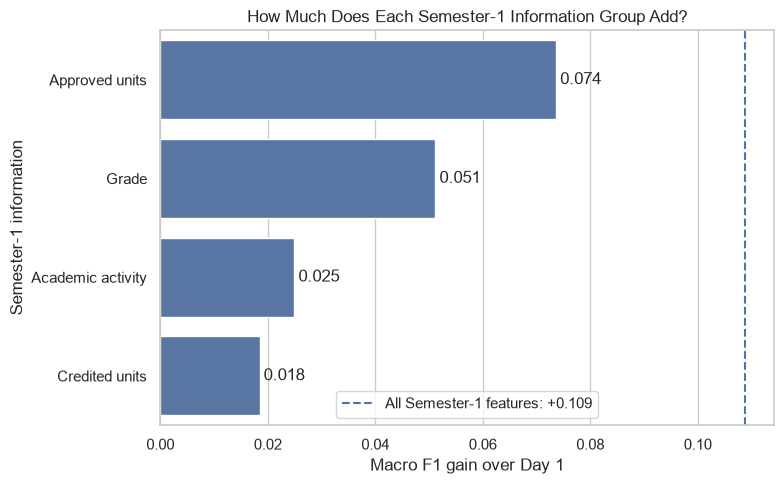

In [14]:
plot_df = (
    add_one_df[
        ~add_one_df["Feature Set"].isin(["Day 1", "After Semester 1"])
    ][["Feature Set", "Δ Macro F1 vs Day 1"]]
    .copy()
)

plot_df["Group"] = plot_df["Feature Set"].str.replace("Day 1 + ", "", regex=False)
plot_df = plot_df.sort_values("Δ Macro F1 vs Day 1", ascending=False)

full_gain = float(
    add_one_df.loc[
        add_one_df["Feature Set"] == "After Semester 1",
        "Δ Macro F1 vs Day 1"
    ].iloc[0]
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=plot_df,
    x="Δ Macro F1 vs Day 1",
    y="Group",
    ax=ax
)

ax.axvline(
    full_gain,
    linestyle="--",
    linewidth=1.5,
    label=f"All Semester-1 features: +{full_gain:.3f}"
)

ax.set_title("How Much Does Each Semester-1 Information Group Add?")
ax.set_xlabel("Macro F1 gain over Day 1")
ax.set_ylabel("Semester-1 information")
ax.legend()

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.savefig(
    "../reports/figures/sem1_add_one_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Approved units provide the largest individual improvement, increasing Macro F1 from 0.550 to 0.623 and recovering approximately 68% of the total Semester-1 gain. Grade also improves Macro F1 substantially (+0.051), followed by academic activity (+0.025) and credited units (+0.018).

These results suggest that successful course completion may contain more predictive information about eventual student outcomes than average grade alone. However, the feature groups may contain overlapping information, so their individual gains should not be interpreted as independent or causal contributions.

## 8.5 Leave-one-group-out analysis

Start with the complete **After Semester 1** model, then remove one information group at a time.

This asks: *Once all other Semester-1 information is available, how much do we lose if this group is unavailable?*

In [15]:
after_sem1_cols = feature_sets["After Semester 1"]

leave_out_results = [
    evaluate_ablation(after_sem1_cols, "After Semester 1")
]

for group_name, group_cols in SEM1_GROUPS.items():
    kept_cols = [
        c for c in after_sem1_cols
        if c not in group_cols
    ]

    leave_out_results.append(
        evaluate_ablation(
            kept_cols,
            f"After Sem 1 - {group_name}"
        )
    )

leave_out_df = pd.DataFrame(leave_out_results)

full_row = leave_out_df.loc[
    leave_out_df["Feature Set"] == "After Semester 1"
].iloc[0]

for metric in METRIC_COLS:
    leave_out_df[f"Loss in {metric}"] = full_row[metric] - leave_out_df[metric]

display(
    leave_out_df[
        ["Feature Set"] + METRIC_COLS +
        ["Loss in Macro F1", "Loss in Enrolled Recall"]
    ].round(3)
)

,Feature Set,Accuracy,Macro F1,Macro Recall,Dropout Recall,Enrolled Recall,Graduate Recall,Loss in Macro F1,Loss in Enrolled Recall
0,After Semester 1,0.698,0.658,0.667,0.683,0.560,0.758,0.000,0.000
1,After Sem 1 - Grade,0.692,0.653,0.662,0.683,0.560,0.744,0.006,0.000
2,After Sem 1 - Approved units,0.664,0.634,0.647,0.627,0.604,0.710,0.025,-0.044
3,After Sem 1 - Academic activity,0.673,0.638,0.646,0.694,0.535,0.710,0.021,0.025
4,After Sem 1 - Credited units,0.693,0.654,0.663,0.669,0.566,0.753,0.005,-0.006


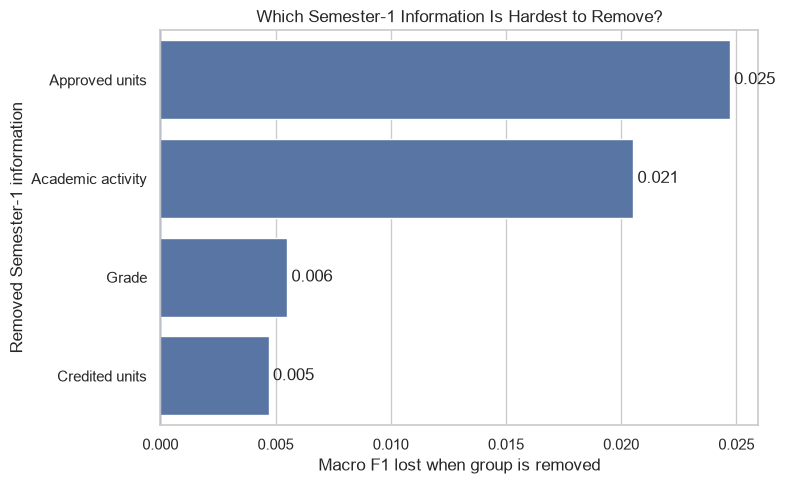

In [16]:
leave_plot_df = (
    leave_out_df[
        leave_out_df["Feature Set"] != "After Semester 1"
    ][["Feature Set", "Loss in Macro F1"]]
    .copy()
)

leave_plot_df["Removed group"] = leave_plot_df["Feature Set"].str.replace(
    "After Sem 1 - ", "", regex=False
)
leave_plot_df = leave_plot_df.sort_values("Loss in Macro F1", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=leave_plot_df,
    x="Loss in Macro F1",
    y="Removed group",
    ax=ax
)

ax.axvline(0, linewidth=1)
ax.set_title("Which Semester-1 Information Is Hardest to Remove?")
ax.set_xlabel("Macro F1 lost when group is removed")
ax.set_ylabel("Removed Semester-1 information")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.savefig(
    "../reports/figures/sem1_leave_one_out_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Removing approved units produces the largest decrease in Macro F1 (0.025), followed by academic activity (0.021). This supports the add-one-group results and suggests that these groups provide important information that cannot be fully replaced by the remaining Semester-1 variables.

Grade shows a different pattern. Although adding grade alone improves Macro F1 by 0.051, removing it from the full model reduces Macro F1 by only 0.006. This suggests that much of the predictive information in grade may overlap with approved units and other academic measurements. Academic activity, meanwhile, appears to provide more complementary information when the other Semester-1 variables are already included.

## 8.6 Focus on the Enrolled class

Macro F1 is the primary metric, but the project also cares about the difficult **Enrolled** class.

We compare:

- Day 1
- the best single Semester-1 group by Macro F1
- all Semester-1 information

This keeps the presentation focused rather than showing every ablation in another crowded plot.

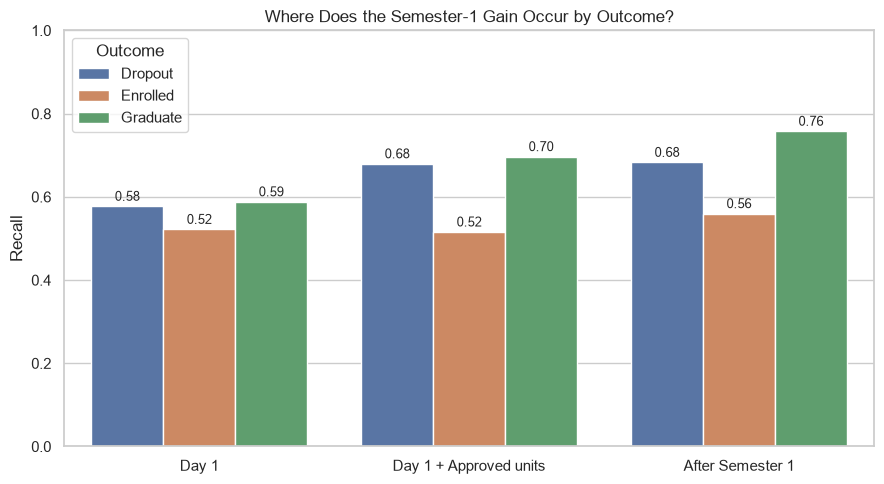

Best single Semester-1 group by Macro F1: Day 1 + Approved units


In [17]:
single_group_rows = add_one_df[
    add_one_df["Feature Set"].str.startswith("Day 1 +")
]

best_single_name = single_group_rows.loc[
    single_group_rows["Macro F1"].idxmax(),
    "Feature Set"
]

recall_compare = add_one_df[
    add_one_df["Feature Set"].isin(
        ["Day 1", best_single_name, "After Semester 1"]
    )
][
    ["Feature Set", "Dropout Recall", "Enrolled Recall", "Graduate Recall"]
].copy()

recall_long = recall_compare.melt(
    id_vars="Feature Set",
    var_name="Outcome",
    value_name="Recall"
)

recall_long["Outcome"] = recall_long["Outcome"].str.replace(
    " Recall", "", regex=False
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=recall_long,
    x="Feature Set",
    y="Recall",
    hue="Outcome",
    ax=ax
)

ax.set_ylim(0, 1)
ax.set_title("Where Does the Semester-1 Gain Occur by Outcome?")
ax.set_xlabel("")
ax.set_ylabel("Recall")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=9)

plt.tight_layout()
plt.savefig(
    "../reports/figures/sem1_ablation_class_recall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Best single Semester-1 group by Macro F1:", best_single_name)

Although approved units provide the largest improvement in overall Macro F1, they do not improve Enrolled recall when added alone. Enrolled recall decreases slightly from 0.522 to 0.516, while Dropout and Graduate recall improve considerably.

Including all Semester-1 variables increases Enrolled recall to 0.560, suggesting that a broader combination of academic information is needed to distinguish students who remain enrolled. This highlights why overall performance alone may not fully capture the model's effectiveness across different student outcomes.

## 8.7 Presentation-ready summary table

This compact table is meant to be directly reusable in Round 2 slides.

The most useful columns are:

- **Macro F1**
- **Gain vs Day 1**
- **Enrolled Recall**

Accuracy and Macro Recall remain available in the detailed tables above.

In [18]:
presentation_table = add_one_df[
    ["Feature Set", "Accuracy", "Macro F1", "Macro Recall",
     "Enrolled Recall", "Δ Macro F1 vs Day 1"]
].copy()

presentation_table = presentation_table.rename(
    columns={"Δ Macro F1 vs Day 1": "Macro F1 gain vs Day 1"}
)

display(presentation_table.round(3))

presentation_table.to_csv(
    "../data/processed/sem1_ablation_summary.csv",
    index=False
)

leave_out_df.to_csv(
    "../data/processed/sem1_leave_one_out_summary.csv",
    index=False
)

,Feature Set,Accuracy,Macro F1,Macro Recall,Enrolled Recall,Macro F1 gain vs Day 1
0,Day 1,0.573,0.550,0.563,0.522,0.000
1,Day 1 + Grade,0.627,0.601,0.611,0.547,0.051
2,Day 1 + Approved units,0.659,0.623,0.631,0.516,0.074
3,Day 1 + Academic activity,0.603,0.575,0.587,0.541,0.025
4,Day 1 + Credited units,0.594,0.568,0.580,0.522,0.018
5,After Semester 1,0.698,0.658,0.667,0.560,0.109


## 8.8 What do the two ablation analyses tell us?

The add-one-group and leave-one-group-out analyses provide complementary perspectives on the importance of Semester-1 information.

**Approved units emerge as the strongest overall predictive group.** They produce the largest Macro F1 improvement when added to Day 1 (+0.074) and the largest performance loss when removed from the complete Semester-1 model (0.025). This suggests that successful course completion contains substantial predictive information about eventual academic outcomes.

**Grade contains useful but potentially redundant information.** Although grade improves Macro F1 considerably when added alone (+0.051), removing it from the full model has only a small effect (0.006). This suggests that other Semester-1 variables may already capture much of the information associated with grade.

**Academic activity provides complementary information.** Its relatively small individual gain (+0.025), combined with a larger removal effect (0.021), suggests that enrollment and evaluation activity may provide additional information when combined with academic performance measures.

**The most useful predictors also depend on which outcome we want to identify.** Removing approved units reduces overall Macro F1 but increases Enrolled recall from 0.560 to 0.604. This suggests a tradeoff between overall classification performance and identifying students who remain enrolled. However, higher Enrolled recall alone does not necessarily indicate better overall identification of Enrolled students, since it may come at the cost of more false positives or reduced performance for other classes.


Overall, the results suggest that the Semester-1 improvement is driven primarily by information about academic progress, with other academic measurements contributing overlapping and complementary predictive signals. These are predictive associations rather than causal effects.

## 8.9 Connection to academic trajectory (Notebook 06)

Notebook 06 examined how first-semester academic performance relates to later academic outcomes and GPA trajectories. Notebook 08 extends this analysis by investigating which types of Semester-1 information contribute most to final-outcome classification.

The ablation results suggest that approved units provide more predictive information than average grade alone. One possible explanation is that the number of successfully completed courses captures academic progress more directly, whereas average grade primarily measures performance among evaluated coursework.

This is particularly relevant because Semester-1 grades contain many zeros, potentially reflecting students with little or no successful academic activity. Approved units may help distinguish students based on actual course completion, even when grades are similar.

At the same time, academic activity contributes additional predictive information beyond grades and approved units, suggesting that both academic achievement and coursework participation are relevant to predicting eventual student outcomes.

Together, these analyses suggest that early academic progress is an important indicator of future student outcomes. However, the ablation results establish predictive value rather than a causal relationship between course completion and graduation or dropout.

## 8.10 Conclusion

The large improvement from Day 1 to After Semester 1 appears to be driven primarily by information about students' actual academic progress. Adding first-semester information increases Macro F1 from 0.550 to 0.658, with particularly large improvements in identifying eventual graduates and dropouts.

Among the Semester-1 feature groups, approved units provide the strongest individual improvement, recovering approximately 68% of the total Macro F1 gain. This suggests that the number of successfully completed curricular units carries substantial predictive information about final student outcomes, potentially more than average grade alone.

The leave-one-group-out analysis further supports this finding. Removing approved units produces the largest decrease in Macro F1 (0.025), followed closely by academic activity (0.021), suggesting that academic activity provides complementary information beyond grades and approved units. Although grade is useful individually, its relatively small removal effect suggests that some of its predictive information overlaps with other first-semester measurements.

However, these improvements are not uniform across classes. Enrolled remains the most difficult class to predict, and removing approved units actually increases Enrolled recall from 0.560 to 0.604 while reducing overall Macro F1. This suggests that the information most useful for distinguishing Dropout and Graduate outcomes is not necessarily the most useful for identifying students who remain enrolled.

Overall, the first-semester performance gain appears to reflect newly available information about academic achievement, course completion, and participation rather than simply the addition of more predictors. These findings describe predictive associations, not causal effects, and are based on a single train/test split.